# Universal Virtual Temperature Sensor — Multi-Dataset Pipeline (v2)

CNN-LSTM-DNN that predicts battery **surface temperature** from `V`, `I`, `Tamb` and `Qacc`.

This notebook extends the single-dataset (Panasonic) pipeline so the model can also learn from **Oxford** and **NASA** data and handle **user-uploaded datasets** with different / missing / extra columns.

| Step | What it does |
|------|--------------|
| 0 | Imports |
| 1 | Config: paths, split definitions, how much of each dataset to use |
| 2 | Panasonic loader (your existing code) + manager's split |
| 3 | Oxford + NASA loaders (subsampled, so the big files stay small) |
| 4 | Universal column mapper for uploaded files (any columns, any units) |
| 5 | Cleaning, resampling to a common time step, universal features |
| 6 | Build train / validation / test sets from all three sources |
| 7 | Scaling, sequences, sample weights, ambient-dropout augmentation |
| 8 | Model (same CNN-LSTM-DNN) + experiment runner |
| 9 | Staged validation: Panasonic → Oxford → NASA, with PASS / FAIL |
| 10 | Save model + scalers + config for the website |
| 11 | Inference function for uploaded datasets |

**Three design changes versus v1** (each one is what makes cross-dataset generalisation possible):

1. **Target is `ΔT = T_surface − T_ambient`**, not absolute temperature. Absolute temperature ties the model to the ambient range it was trained on (−10 to 25 °C); Oxford runs at 40 °C.
2. **Current is normalised to C-rate** (`I / nominal capacity`) and `Qacc` is re-computed per file by coulomb counting. A 0.74 Ah pouch cell and a 2.9 Ah 18650 then look comparable.
3. **Everything is resampled to a common time step** (default 1 s), because the three datasets are sampled at different rates.

# Step 0 — Imports

In [1]:
import os
import re
import json
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy.io import loadmat
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Conv1D, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

# Step 1 — Configuration

In [2]:
# ---------- Paths ----------
PROJECT_ROOT = r"C:\Users\medha\OneDrive\Documents\TrustSenseBMS"

DATA_DIR    = os.path.join(PROJECT_ROOT, "data")                       # Panasonic .mat files (as before)
OXFORD_PATH = os.path.join(PROJECT_ROOT, "data_oxford",
                           "Oxford_Battery_Degradation_Dataset_1.mat") # one big file with Cell1..Cell8
OXFORD_DC_PATH = os.path.join(PROJECT_ROOT, "data_oxford",
                              "ExampleDC_C1.mat")                      # optional: Artemis drive-cycle example
NASA_DIR    = os.path.join(PROJECT_ROOT, "data_nasa")                  # B0005.mat, B0006.mat, ...
OUTPUT_DIR  = os.path.join(PROJECT_ROOT, "artifacts")                  # model + scalers + config end up here
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------- Common time base ----------
RESAMPLE_DT_S = 1.0     # every dataset is brought to this time step (seconds)
WINDOW_LENGTH = 60      # samples per sequence -> 60 s of context at 1 s. Try 120 or 300 later.
TRAIN_STRIDE  = 5       # keep every 5th training window (neighbouring windows are near-duplicates)
MAX_GAP_S     = 30.0    # a time gap larger than this splits a file into separate segments

# ---------- Training behaviour ----------
TAMB_DROPOUT    = 0.2   # fraction of training windows where ambient temp is hidden (teaches "Tamb missing")
MAX_SOURCE_WEIGHT = 5.0 # cap on how much a small dataset is up-weighted against Panasonic
PASS_MAE_DEGC   = 1.0   # Stage PASS threshold on absolute temperature MAE (ask your manager for the real target)

# ---------- Nominal cell capacities (Ah) used for C-rate normalisation ----------
CELL_CAPACITY_AH = {"panasonic": 2.9, "oxford": 0.74, "nasa": 2.0}
DEFAULT_CAPACITY_AH = 2.0   # used for uploaded files when the user does not give a capacity

# ---------- Panasonic split (manager's plan) ----------
# (profile, chamber temperature in degC). File names are looked up automatically.
# Edit freely, or replace this whole block with your old `selected_files` lists.
PANASONIC_SPLIT = {
    "train": [
        ("UDDS", 25), ("HWFET", 25), ("US06", 10), ("Cycle_1", 0), ("Cycle_2", -10),
        # ("<mixed-profile-token>", 25),   # manager's "Mixed Cycle 1 / 2": use the exact token from your file names
    ],
    "validation": [("LA92", 25), ("HWFET", 10)],
    "test": {
        "Test1 UDDS @ -10C":     [("UDDS", -10)],
        "Test2 US06 @ unseen T": [("US06", 0)],     # pick a temperature that US06 was NOT trained on
        # "Test3 Temp-rise":     [("<profile>", <temp>)],   # Tamb varies with time (see note below)
    },
}
# Profiles listed here keep their *measured* chamber temperature instead of the constant
# that fix_chamber_temp() would force from the file name (needed for the temperature-rise test).
KEEP_MEASURED_CHAMBER_TEMP = []   # e.g. ["Trise"]

# ---------- Oxford: use only a few cells and a few cycles per cell ----------
# Cell8 is held out completely -> zero-shot "different cell / aging" test.
OXFORD_SPLIT = {"train": ["Cell1", "Cell3"], "validation": ["Cell2"], "test": ["Cell8"]}
OXFORD_CYCLES_PER_CELL = 4      # evenly spaced over the cell's life (fresh -> aged)
OXFORD_CHAMBER_TEMP_C  = 40.0   # Oxford readme: Binder chamber at 40 degC
OXFORD_1C_CURRENT_A    = 0.74   # Oxford readme: 1-C cycles at 740 mA

# ---------- NASA: use only a few batteries and a few cycles per battery ----------
NASA_SPLIT = {"train": ["B0005", "B0006"], "validation": ["B0007"], "test": ["B0018"]}
NASA_CYCLES_PER_BATTERY = 8     # half charge, half discharge cycles, evenly spaced over life

# ---------- Universal model schema (do not change after training) ----------
FEATURE_COLUMNS = [
    "voltage_v",          # V
    "c_rate",             # I / nominal capacity  (signed: discharge negative)
    "qacc_norm",          # coulomb-counted charge since file start / nominal capacity
    "chamber_temp_degC",  # Tamb
    "power_norm",         # V * C-rate
    "c_rate_sq",          # C-rate^2  (Joule-heating proxy)
]
MASK_COLUMNS   = ["tamb_available"]          # 1 = ambient temp is real, 0 = it was missing
TARGET_COLUMN  = "delta_temp_degC"           # T_surface - T_ambient
TAMB_IDX       = FEATURE_COLUMNS.index("chamber_temp_degC")
N_MODEL_INPUTS = len(FEATURE_COLUMNS) + len(MASK_COLUMNS)

# Registry filled by the loaders: file_name -> {"source": ..., "capacity_ah": ...}
file_meta = {}

# Step 2 — Panasonic loader (existing code) + automatic file lookup

In [3]:
def load_battery_file(file_path):
    """
    Load one Panasonic .mat experiment and return
    a standardized battery DataFrame.
    """

    mat_data = loadmat(file_path)
    meas = mat_data["meas"]

    df = pd.DataFrame({
        "time_s": meas["Time"][0, 0].flatten(),
        "voltage_v": meas["Voltage"][0, 0].flatten(),
        "current_a": meas["Current"][0, 0].flatten(),
        "ah": meas["Ah"][0, 0].flatten(),
        "battery_temp_degC": meas["Battery_Temp_degC"][0, 0].flatten(),
        "chamber_temp_degC": meas["Chamber_Temp_degC"][0, 0].flatten()
    })

    return df


def fix_chamber_temp(df, file_name):
    df = df.copy()

    if "n10degC" in file_name:
        df["chamber_temp_degC"] = -10.0

    elif "10degC" in file_name:
        df["chamber_temp_degC"] = 10.0

    elif "25degC" in file_name:
        df["chamber_temp_degC"] = 25.0

    return df

In [4]:
def find_panasonic_file(profile, temp_c, data_dir=DATA_DIR):
    """
    Find a Panasonic file by (profile, temperature) instead of typing the long
    timestamped file name. Example: ("UDDS", -10) -> '06-07-17_08.39 n10degC_UDDS_Pan18650PF.mat'
    """
    token = f"n{abs(temp_c)}degC" if temp_c < 0 else f"{temp_c}degC"

    # (?<![0-9n]) stops "0degC" matching inside "10degC" / "n10degC"
    pattern = re.compile(rf"(?<![0-9n]){re.escape(token)}_{re.escape(profile)}_Pan18650PF\.mat$")

    matches = [f for f in os.listdir(data_dir) if pattern.search(f)]
    return matches[0] if matches else None


def load_panasonic_files(specs, data_dir=DATA_DIR):
    """Load a list of (profile, temp) specs -> {file_name: raw DataFrame}."""
    data = {}

    for profile, temp_c in specs:
        file_name = find_panasonic_file(profile, temp_c, data_dir)

        if file_name is None:
            print(f"  [skip] no Panasonic file found for {profile} @ {temp_c} degC")
            continue

        df = load_battery_file(os.path.join(data_dir, file_name))

        if profile not in KEEP_MEASURED_CHAMBER_TEMP:
            df = fix_chamber_temp(df, file_name)

        data[file_name] = df[["time_s", "voltage_v", "current_a",
                              "chamber_temp_degC", "battery_temp_degC"]]
        file_meta[file_name] = {"source": "panasonic",
                                "capacity_ah": CELL_CAPACITY_AH["panasonic"]}

    return data

# Step 3 — Oxford and NASA loaders

Both datasets are large, so each loader takes **only a few cells and a few cycles**, spread evenly over the cell's life (fresh → aged).

- **Oxford** (`Cell1..Cell8`, Kokam 740 mAh pouch, 40 °C chamber): the file has `t, v, q, T` but **no current column** (1-C steps are constant-current), so current is rebuilt as ±0.74 A while charge is actually moving.
- **NASA** (`B00xx`, 18650 2 Ah): `Time, Voltage_measured, Current_measured, Temperature_measured` plus an `ambient_temperature` per cycle.

In [5]:
def pick_evenly(items, n):
    """Pick n items spread evenly across a list (always includes first and last)."""
    items = list(items)
    if len(items) <= n:
        return items
    idx = np.unique(np.linspace(0, len(items) - 1, n).round().astype(int))
    return [items[i] for i in idx]


def _load_mat(mat_path, variable_names=None):
    try:
        return loadmat(mat_path, variable_names=variable_names,
                       squeeze_me=True, struct_as_record=False)
    except NotImplementedError:
        raise RuntimeError(
            f"{os.path.basename(mat_path)} is a MATLAB v7.3 (HDF5) file. "
            "Install 'mat73' (pip install mat73) and load it with mat73.loadmat instead."
        )

In [6]:
def derive_step_current(t, q_mAh, nominal_current_a, sign):
    """
    Oxford 1-C files have no current column. The step is constant-current, so we rebuild
    the current as +/- nominal while charge is really moving (|dq/dt| well above zero)
    and 0 A during rests.
    """
    dq_dt_mA = np.gradient(q_mAh, t) * 3600.0                      # mAh/s -> mA
    dq_dt_mA = pd.Series(dq_dt_mA).rolling(11, center=True, min_periods=1).median().to_numpy()
    active = np.abs(dq_dt_mA) > 0.5 * nominal_current_a * 1000.0
    return sign * nominal_current_a * active.astype(float)


def load_oxford_cells(mat_path, cell_names, cycles_per_cell=OXFORD_CYCLES_PER_CELL):
    """
    Return {cell_name: {file_name: raw DataFrame}} using only a few characterisation
    cycles per cell (C1ch = 1C charge, C1dc = 1C discharge).
    """
    mat = _load_mat(mat_path, variable_names=cell_names)
    out = {}

    for cell_name in cell_names:
        cell = mat[cell_name]
        cycle_names = sorted(n for n in cell._fieldnames if n.startswith("cyc"))
        out[cell_name] = {}

        for cyc in pick_evenly(cycle_names, cycles_per_cell):
            cyc_struct = getattr(cell, cyc)

            for step_name, sign in [("C1ch", +1.0), ("C1dc", -1.0)]:
                step = getattr(cyc_struct, step_name)

                t = np.atleast_1d(np.asarray(step.t, dtype=float))
                v = np.atleast_1d(np.asarray(step.v, dtype=float))
                q = np.atleast_1d(np.asarray(step.q, dtype=float))
                T = np.atleast_1d(np.asarray(step.T, dtype=float))

                # np.gradient needs strictly increasing time
                t, keep = np.unique(t, return_index=True)
                v, q, T = v[keep], q[keep], T[keep]

                df = pd.DataFrame({
                    "time_s": t - t[0],
                    "voltage_v": v,
                    "current_a": derive_step_current(t, q, OXFORD_1C_CURRENT_A, sign),
                    "chamber_temp_degC": OXFORD_CHAMBER_TEMP_C,
                    "battery_temp_degC": T,
                })

                file_name = f"oxford_{cell_name}_{cyc}_{step_name}"
                out[cell_name][file_name] = df
                file_meta[file_name] = {"source": "oxford",
                                        "capacity_ah": CELL_CAPACITY_AH["oxford"]}

    return out

In [7]:
def load_oxford_drive_cycle(mat_path):
    """
    OPTIONAL: the single Artemis urban drive-cycle discharge in ExampleDC_C1.mat.
    It is the only truly dynamic Oxford profile (current -5 A ... +1.6 A), so it is a
    good extra *test* of dynamic behaviour. Layout per the Oxford readme: .ch / .dc ->
    t, v, q, T, i. If your copy differs, the function prints what it found.
    """
    mat = _load_mat(mat_path)
    keys = [k for k in mat if not k.startswith("__")]

    dc = None
    for k in keys:
        obj = mat[k]
        if k == "dc":
            dc = obj
        elif hasattr(obj, "_fieldnames") and "dc" in obj._fieldnames:
            dc = obj.dc

    if dc is None:
        print("  [skip] could not find the discharge struct. Top-level keys:", keys)
        return {}

    t = np.asarray(dc.t, dtype=float).flatten()
    i = np.asarray(dc.i, dtype=float).flatten()
    if np.nanpercentile(np.abs(i), 99) > 20:      # looks like mA -> A
        i = i / 1000.0

    t, keep = np.unique(t, return_index=True)
    df = pd.DataFrame({
        "time_s": t - t[0],
        "voltage_v": np.asarray(dc.v, dtype=float).flatten()[keep],
        "current_a": i[keep],                       # discharge negative, regen positive
        "chamber_temp_degC": OXFORD_CHAMBER_TEMP_C,
        "battery_temp_degC": np.asarray(dc.T, dtype=float).flatten()[keep],
    })

    file_name = "oxford_ExampleDC_Artemis_dc"
    file_meta[file_name] = {"source": "oxford", "capacity_ah": CELL_CAPACITY_AH["oxford"]}
    return {file_name: df}

In [8]:
def load_nasa_battery(mat_path, battery_name, cycles_per_battery=NASA_CYCLES_PER_BATTERY):
    """
    Return {file_name: raw DataFrame} for a few charge and discharge cycles of one NASA battery.
    Sign convention is forced to: charge = +, discharge = -  (we know the cycle type, so we
    do not rely on the sign stored in the file).
    """
    mat = _load_mat(mat_path, variable_names=[battery_name])
    cycles = np.atleast_1d(mat[battery_name].cycle)

    charge_ids    = [k for k, c in enumerate(cycles) if str(c.type) == "charge"]
    discharge_ids = [k for k, c in enumerate(cycles) if str(c.type) == "discharge"]

    half = max(cycles_per_battery // 2, 1)
    chosen = pick_evenly(charge_ids, half) + pick_evenly(discharge_ids, half)

    data = {}
    for k in chosen:
        c = cycles[k]
        d = c.data
        sign = +1.0 if str(c.type) == "charge" else -1.0

        df = pd.DataFrame({
            "time_s": np.atleast_1d(np.asarray(d.Time, dtype=float)),
            "voltage_v": np.atleast_1d(np.asarray(d.Voltage_measured, dtype=float)),
            "current_a": sign * np.abs(np.atleast_1d(np.asarray(d.Current_measured, dtype=float))),
            "chamber_temp_degC": float(c.ambient_temperature),   # per-cycle ambient from the file
            "battery_temp_degC": np.atleast_1d(np.asarray(d.Temperature_measured, dtype=float)),
        })

        file_name = f"nasa_{battery_name}_cyc{k:04d}_{c.type}"
        data[file_name] = df
        file_meta[file_name] = {"source": "nasa",
                                "capacity_ah": CELL_CAPACITY_AH["nasa"]}

    return data

# Step 4 — Universal column mapper (for uploaded datasets)

This is what lets the website accept files with **different column names, units, extra columns, or missing optional columns**.

| Signal | Status | If missing |
|--------|--------|-----------|
| time | required | can be rebuilt from a sampling rate |
| voltage | **required** | upload is rejected with a clear message |
| current | **required** | upload is rejected (heat generation cannot be inferred without it) |
| ambient temp | optional | user-supplied constant, else 25 °C + `tamb_available = 0` |
| surface temp | optional | prediction still runs; only validation metrics are skipped |
| capacity / Ah | optional | Ah is never trusted; `Qacc` is always re-computed from current |
| any extra column | ignored | listed in the report |

In [9]:
COLUMN_ALIASES = {
    "time_s":            ["time", "time_s", "t", "timestamp", "test_time", "elapsed_time", "seconds", "datetime"],
    "voltage_v":         ["voltage", "voltage_v", "v", "terminal_voltage", "cell_voltage", "voltage_measured", "volt", "volts"],
    "current_a":         ["current", "current_a", "i", "amps", "amp", "current_measured", "cell_current"],
    "chamber_temp_degC": ["ambient", "ambient_temp", "ambient_temperature", "tamb", "t_amb",
                          "chamber_temp", "chamber_temperature", "environment_temp", "env_temp"],
    "battery_temp_degC": ["battery_temp", "battery_temperature", "cell_temp", "cell_temperature",
                          "surface_temp", "temperature", "temp", "temperature_measured", "t_cell", "t_surf"],
}


def _norm(name):
    """'Battery_Temp_degC' / 'battery temp (degC)' -> 'battery_temp_degc'"""
    return re.sub(r"[^a-z0-9]+", "_", str(name).strip().lower()).strip("_")


def map_columns(df_raw, column_map=None):
    """
    Match the columns of an uploaded file to the canonical names.
    1) user-forced mapping  2) token match against aliases (most specific alias wins)
    3) fuzzy spelling match. Returns {canonical_name: raw_column_name}.
    """
    mapping = dict(column_map or {})
    for canon, raw_col in mapping.items():
        if raw_col not in df_raw.columns:
            raise ValueError(f"column_map says {canon} -> '{raw_col}', but that column does not exist.")

    col_tokens = {c: set(_norm(c).split("_")) for c in df_raw.columns}

    candidates = []
    for canon, aliases in COLUMN_ALIASES.items():
        if canon in mapping:
            continue
        for alias in aliases:
            a_tok = set(_norm(alias).split("_"))
            for col, c_tok in col_tokens.items():
                if col in mapping.values():
                    continue
                if a_tok <= c_tok:                         # all alias words appear in the column name
                    score = 10 * len(a_tok) - (len(c_tok) - len(a_tok))
                    candidates.append((score, canon, col))

    for score, canon, col in sorted(candidates, key=lambda x: -x[0]):
        if canon not in mapping and col not in mapping.values():
            mapping[canon] = col

    # fuzzy fallback for typos such as "Voltge"
    for canon, aliases in COLUMN_ALIASES.items():
        if canon in mapping:
            continue
        free = {_norm(c): c for c in df_raw.columns if c not in mapping.values()}
        for alias in aliases:
            hit = difflib.get_close_matches(_norm(alias), list(free), n=1, cutoff=0.85)
            if hit:
                mapping[canon] = free[hit[0]]
                break

    return mapping

In [10]:
def standardize_uploaded_df(df_raw, column_map=None, n_series=1, n_parallel=1,
                            current_sign="discharge_negative", time_unit="auto",
                            sample_rate_hz=None, ambient_temp_degC=None):
    """
    Convert ANY uploaded battery table into the canonical raw format:
        time_s, voltage_v, current_a, chamber_temp_degC, battery_temp_degC
    Returns (df, report). Raises ValueError if voltage / current / time cannot be found.

    n_series / n_parallel : pack layout. Pack voltage is divided by n_series and pack current by
                            n_parallel so the model always sees ONE cell.
    current_sign          : "discharge_negative" (training convention) or "discharge_positive".
    time_unit             : "auto" (numbers = seconds, text = datetime) or "s", "ms", "min", "h".
    """
    report = {"mapping": {}, "ignored_columns": [], "warnings": [], "tamb_available": True}
    mapping = map_columns(df_raw, column_map)
    report["mapping"] = dict(mapping)
    report["ignored_columns"] = [c for c in df_raw.columns if c not in mapping.values()]

    # ---------- required signals ----------
    missing = [c for c in ("voltage_v", "current_a") if c not in mapping]
    if missing:
        raise ValueError(
            f"Required column(s) not found: {missing}. Columns in the file: {list(df_raw.columns)}. "
            "Pass column_map={'voltage_v': '<your column>', 'current_a': '<your column>'} to map them manually."
        )

    # ---------- time ----------
    if "time_s" in mapping:
        raw_t = df_raw[mapping["time_s"]]
        if time_unit == "auto":
            if pd.api.types.is_numeric_dtype(raw_t):
                t = raw_t.astype(float).to_numpy()
            else:
                stamps = pd.to_datetime(raw_t)
                t = (stamps - stamps.iloc[0]).dt.total_seconds().to_numpy()
        else:
            t = raw_t.astype(float).to_numpy() * {"s": 1.0, "ms": 1e-3, "min": 60.0, "h": 3600.0}[time_unit]
    elif sample_rate_hz:
        t = np.arange(len(df_raw)) / float(sample_rate_hz)
        report["warnings"].append(f"No time column: time rebuilt from sample_rate_hz={sample_rate_hz}.")
    else:
        raise ValueError("No time column found. Give sample_rate_hz=<samples per second> or column_map={'time_s': ...}.")

    # ---------- voltage (-> one cell, volts) ----------
    v_col = mapping["voltage_v"]
    v = df_raw[v_col].astype(float).to_numpy()
    if "mv" in _norm(v_col).split("_"):
        v = v * 1e-3
    v = v / n_series
    if np.nanpercentile(v, 99) > 5.0:
        report["warnings"].append("Voltage per cell is above 5 V: check units (mV?) or set n_series for a pack.")

    # ---------- current (-> one cell, amps, discharge negative) ----------
    i_col = mapping["current_a"]
    i = df_raw[i_col].astype(float).to_numpy()
    if "ma" in _norm(i_col).split("_"):
        i = i * 1e-3
    i = i / n_parallel
    if current_sign == "discharge_positive":
        i = -i
    corr = np.corrcoef(np.cumsum(np.nan_to_num(i)), np.nan_to_num(v))[0, 1]
    if np.isfinite(corr) and corr < -0.3:
        report["warnings"].append("Current sign looks inverted (voltage falls while net charge rises). "
                                  "Check current_sign.")

    # ---------- temperatures ----------
    def _to_celsius(series, name):
        x = series.astype(float).to_numpy()
        if np.nanmedian(x) > 200:                      # Kelvin
            x = x - 273.15
            report["warnings"].append(f"{name} looked like Kelvin and was converted to degC.")
        return x

    if "battery_temp_degC" in mapping:
        t_surf = _to_celsius(df_raw[mapping["battery_temp_degC"]], "Surface temperature")
    else:
        t_surf = np.full(len(df_raw), np.nan)
        report["warnings"].append("No surface-temperature column: predictions only, no validation metrics.")

    if "chamber_temp_degC" in mapping:
        t_amb = _to_celsius(df_raw[mapping["chamber_temp_degC"]], "Ambient temperature")
        t_amb = pd.Series(t_amb).ffill().bfill().to_numpy()
    elif ambient_temp_degC is not None:
        t_amb = np.full(len(df_raw), float(ambient_temp_degC))
    else:
        t_amb = np.full(len(df_raw), 25.0)
        report["tamb_available"] = False
        report["warnings"].append("No ambient temperature: assumed 25 degC and flagged as unavailable "
                                  "(the model was trained to cope, but accuracy is lower).")

    df = pd.DataFrame({"time_s": t, "voltage_v": v, "current_a": i,
                       "chamber_temp_degC": t_amb, "battery_temp_degC": t_surf})
    return df, report

# Step 5 — Cleaning, resampling and universal features

In [11]:
def clean_battery_df(df):
    df = df.copy()

    df = df.sort_values("time_s").reset_index(drop=True)

    # Remove completely identical rows
    df = df.drop_duplicates().reset_index(drop=True)

    # NEW: resampling needs strictly increasing time -> keep the first row of a repeated timestamp
    df = df.drop_duplicates(subset="time_s").reset_index(drop=True)

    # Remove remaining missing values (ignore columns that are entirely empty,
    # e.g. no surface sensor in an uploaded file)
    usable = [c for c in df.columns if df[c].notna().any()]
    df = df.dropna(subset=usable).reset_index(drop=True)

    return df

In [12]:
def resample_to_fixed_dt(df, dt=RESAMPLE_DT_S, max_gap_s=MAX_GAP_S):
    """
    Bring a file onto a uniform time grid and return a LIST of segments.
      - faster than dt (Panasonic 10 Hz): average inside each bin (keeps the I^2 heating information)
      - slower than dt (NASA, ~seconds):   linear interpolation
      - gaps longer than max_gap_s split the file (we never interpolate across a gap)
    """
    df = df.copy()
    df["current_sq_a2"] = df["current_a"] ** 2          # averaged with everything else -> true mean I^2

    value_cols = [c for c in df.columns if c != "time_s"]
    t_all = df["time_s"].to_numpy(dtype=float)

    native_dt = np.median(np.diff(t_all)) if len(t_all) > 1 else dt
    gap_limit = max(max_gap_s, 5.0 * native_dt)
    segments = np.split(np.arange(len(df)), np.where(np.diff(t_all) > gap_limit)[0] + 1)

    out = []
    for seg_idx in segments:
        if len(seg_idx) < 2:
            continue

        seg = df.iloc[seg_idx]
        t = seg["time_s"].to_numpy(dtype=float)
        t = t - t[0]
        grid = np.arange(0.0, t[-1] + 1e-9, dt)
        seg_native_dt = np.median(np.diff(t))

        res = {"time_s": grid}
        for col in value_cols:
            y = seg[col].to_numpy(dtype=float)

            if np.isnan(y).all():                       # e.g. no surface sensor
                res[col] = np.full(len(grid), np.nan)

            elif seg_native_dt < 0.75 * dt:             # downsample: bin average
                bins = np.floor(t / dt).astype(int)
                sums = np.bincount(bins, weights=y, minlength=len(grid))
                cnts = np.bincount(bins, minlength=len(grid))
                avg = np.full(len(grid), np.nan)
                filled = cnts > 0
                avg[filled] = sums[filled] / cnts[filled]
                if (~filled).any():                     # rare empty bins -> interpolate
                    avg = np.interp(grid, grid[filled], avg[filled])
                res[col] = avg

            else:                                       # upsample / same rate: interpolate
                res[col] = np.interp(grid, t, y)

        out.append(pd.DataFrame(res))

    return out

In [13]:
def add_features(df, capacity_ah, tamb_available=1.0, dt=RESAMPLE_DT_S):
    """
    Universal features. Everything is normalised by nominal capacity so cells of
    different size (0.74 Ah pouch, 2 Ah and 2.9 Ah 18650) become comparable.
    """
    df = df.copy()

    # Coulomb counting from file start (discharge negative), in Ah
    qacc_ah = np.cumsum(df["current_a"].to_numpy()) * dt / 3600.0

    df["c_rate"]     = df["current_a"] / capacity_ah
    df["qacc_norm"]  = qacc_ah / capacity_ah
    df["power_norm"] = df["voltage_v"] * df["c_rate"]
    df["c_rate_sq"]  = df["current_sq_a2"] / capacity_ah ** 2

    # Target: how far the surface is above ambient (NaN if the file has no surface sensor)
    df[TARGET_COLUMN] = df["battery_temp_degC"] - df["chamber_temp_degC"]

    df["tamb_available"] = float(tamb_available)
    return df

In [14]:
def build_dataset_dict(raw_dict):
    """
    raw {file_name: DataFrame}  ->  clean -> resample -> features  ->  {file_name: DataFrame}
    A file with big time gaps becomes several entries called  <name>#seg0, <name>#seg1, ...
    """
    out = {}
    for name, df in raw_dict.items():
        capacity = file_meta[name]["capacity_ah"]
        segments = resample_to_fixed_dt(clean_battery_df(df))

        for k, seg in enumerate(segments):
            key = name if len(segments) == 1 else f"{name}#seg{k}"
            out[key] = add_features(seg, capacity)
            file_meta[key] = dict(file_meta[name])

    return out

# Step 6 — Build train / validation / test sets from all sources

In [15]:
# ---------- Panasonic ----------
print("PANASONIC")
raw_train, raw_val = {}, {}
raw_test_sets = {}

raw_train.update(load_panasonic_files(PANASONIC_SPLIT["train"]))
raw_val.update(load_panasonic_files(PANASONIC_SPLIT["validation"]))

for set_name, specs in PANASONIC_SPLIT["test"].items():
    files = load_panasonic_files(specs)
    if files:
        raw_test_sets[f"Panasonic | {set_name}"] = files

# ---------- Oxford ----------
if os.path.exists(OXFORD_PATH):
    print("OXFORD")
    all_cells = OXFORD_SPLIT["train"] + OXFORD_SPLIT["validation"] + OXFORD_SPLIT["test"]
    oxford = load_oxford_cells(OXFORD_PATH, all_cells)

    for cell in OXFORD_SPLIT["train"]:
        raw_train.update(oxford[cell])
    for cell in OXFORD_SPLIT["validation"]:
        raw_val.update(oxford[cell])
    for cell in OXFORD_SPLIT["test"]:
        raw_test_sets[f"Oxford | {cell} (held-out cell)"] = oxford[cell]

    if os.path.exists(OXFORD_DC_PATH):
        drive_cycle = load_oxford_drive_cycle(OXFORD_DC_PATH)
        if drive_cycle:
            raw_test_sets["Oxford | Artemis drive cycle (dynamic)"] = drive_cycle
else:
    print("Oxford file not found, skipping:", OXFORD_PATH)

# ---------- NASA ----------
nasa_files_ok = all(
    os.path.exists(os.path.join(NASA_DIR, f"{b}.mat"))
    for b in sum(NASA_SPLIT.values(), [])
)
if nasa_files_ok:
    print("NASA")
    nasa = {b: load_nasa_battery(os.path.join(NASA_DIR, f"{b}.mat"), b)
            for b in sum(NASA_SPLIT.values(), [])}

    for b in NASA_SPLIT["train"]:
        raw_train.update(nasa[b])
    for b in NASA_SPLIT["validation"]:
        raw_val.update(nasa[b])
    for b in NASA_SPLIT["test"]:
        raw_test_sets[f"NASA | {b} (held-out battery)"] = nasa[b]
else:
    print("NASA files not all found in", NASA_DIR, "- skipping NASA")

PANASONIC
  [skip] no Panasonic file found for HWFET @ 25 degC
  [skip] no Panasonic file found for Cycle_1 @ 0 degC
  [skip] no Panasonic file found for Cycle_2 @ -10 degC
  [skip] no Panasonic file found for US06 @ 0 degC
Oxford file not found, skipping: C:\Users\medha\OneDrive\Documents\TrustSenseBMS\data_oxford\Oxford_Battery_Degradation_Dataset_1.mat
NASA files not all found in C:\Users\medha\OneDrive\Documents\TrustSenseBMS\data_nasa - skipping NASA


In [16]:
# Clean + resample + features for every split
train_data = build_dataset_dict(raw_train)
val_data   = build_dataset_dict(raw_val)
test_sets  = {name: build_dataset_dict(files) for name, files in raw_test_sets.items()}

def summarize(data_dict, title):
    print(f"\n{title}")
    for name, df in data_dict.items():
        print(f"  {file_meta[name]['source']:<10} {name[:60]:<60} {len(df):>8,} samples")

summarize(train_data, "TRAIN")
summarize(val_data, "VALIDATION")
for set_name, d in test_sets.items():
    summarize(d, f"TEST  [{set_name}]")

# Quick look at how much signal each source actually carries
rows = []
for name, df in {**train_data, **val_data}.items():
    rows.append({"source": file_meta[name]["source"], "delta_T_max": df[TARGET_COLUMN].max(),
                 "c_rate_abs_max": df["c_rate"].abs().max(), "tamb": df["chamber_temp_degC"].mean()})
display_df = pd.DataFrame(rows).groupby("source").agg(["min", "max"]).round(2)
print("\nPer-source ranges (shows how different the datasets are):")
print(display_df)


TRAIN
  panasonic  03-21-17_00.29 25degC_UDDS_Pan18650PF.mat                      22,448 samples
  panasonic  03-27-17_09.06 10degC_US06_Pan18650PF.mat                       4,211 samples

VALIDATION
  panasonic  03-21-17_09.38 25degC_LA92_Pan18650PF.mat                      14,104 samples
  panasonic  03-27-17_09.06 10degC_HWFET_Pan18650PF.mat                      7,052 samples

TEST  [Panasonic | Test1 UDDS @ -10C]
  panasonic  06-07-17_08.39 n10degC_UDDS_Pan18650PF.mat                     10,975 samples

Per-source ranges (shows how different the datasets are):
          delta_T_max       c_rate_abs_max        tamb      
                  min   max            min   max   min   max
source                                                      
panasonic        2.04  8.93           1.81  6.24  10.0  25.0


# Step 7 — Scaling, sequences, sample weights, ambient-dropout

- Scalers are fit **only on training data** (same rule as before).
- Sequences are built per file, so a window never crosses a file boundary (same rule as before).
- Panasonic is far bigger than Oxford/NASA, so each source gets a **sample weight** (capped) to stop it dominating.
- For `TAMB_DROPOUT` of the training windows, ambient temperature is hidden (value → 0, mask → 0). This teaches the model to behave sensibly when an uploaded file has no ambient column.

In [17]:
def fit_scalers(data_dict):
    X_all = np.concatenate([df[FEATURE_COLUMNS].values for df in data_dict.values()])
    y_all = np.concatenate([df[TARGET_COLUMN].values for df in data_dict.values()])

    feature_scaler = StandardScaler().fit(X_all)
    target_scaler  = StandardScaler().fit(y_all.reshape(-1, 1))
    return feature_scaler, target_scaler


def create_sequences(X, y, window_length=60, stride=1):
    """
    [Time 1 ... Time W] -> target at Time W.   (same logic as before, now vectorised + stride)
    """
    if len(X) < window_length:
        return np.empty((0, window_length, X.shape[1])), np.empty((0,))

    windows = np.lib.stride_tricks.sliding_window_view(X, window_length, axis=0)   # (N-W+1, F, W)
    X_seq = windows.transpose(0, 2, 1)[::stride].copy()
    y_seq = y[window_length - 1:][::stride]
    return X_seq, y_seq

In [18]:
def build_arrays(data_dict, feature_scaler, target_scaler, stride=1):
    """
    Scale every file, cut it into windows and stack everything.
    Also returns the raw ambient / surface temperature at the END of each window so that
    predictions can be converted back:  T_pred = dT_pred + Tamb.
    """
    X_list, y_list, tamb_list, temp_list, src_list = [], [], [], [], []

    for name, df in data_dict.items():
        if len(df) < WINDOW_LENGTH:
            continue

        X = np.hstack([feature_scaler.transform(df[FEATURE_COLUMNS].values),
                       df[MASK_COLUMNS].values])
        y = target_scaler.transform(df[[TARGET_COLUMN]].values).flatten()

        X_seq, y_seq = create_sequences(X, y, WINDOW_LENGTH, stride)

        X_list.append(X_seq)
        y_list.append(y_seq)
        tamb_list.append(df["chamber_temp_degC"].values[WINDOW_LENGTH - 1:][::stride])
        temp_list.append(df["battery_temp_degC"].values[WINDOW_LENGTH - 1:][::stride])
        src_list += [file_meta[name]["source"]] * len(X_seq)

    if not X_list:
        raise ValueError("No file is long enough to build a single window.")

    return {
        "X": np.concatenate(X_list), "y": np.concatenate(y_list),
        "tamb": np.concatenate(tamb_list), "temp": np.concatenate(temp_list),
        "source": np.array(src_list),
    }


def apply_tamb_dropout(X, rate=TAMB_DROPOUT, seed=42):
    """Hide ambient temperature in a random fraction of windows (value -> 0 = mean, mask -> 0)."""
    X = X.copy()
    drop = np.random.default_rng(seed).random(len(X)) < rate
    X[drop, :, TAMB_IDX] = 0.0
    X[drop, :, -1] = 0.0
    return X


def compute_source_weights(sources, max_weight=MAX_SOURCE_WEIGHT):
    """Equalise the influence of each dataset (capped), mean weight = 1."""
    sources = np.asarray(sources)
    labels, counts = np.unique(sources, return_counts=True)
    per_source = {l: len(sources) / (len(labels) * c) for l, c in zip(labels, counts)}
    w = np.array([min(per_source[s], max_weight) for s in sources])
    return w / w.mean()

# Step 8 — Model (same CNN-LSTM-DNN) and experiment runner

The architecture is unchanged. Only the input has one extra channel (`tamb_available`).
`run_experiment` trains on whichever sources you pass, so the same code gives the three models needed for the comparison: **Panasonic only → + Oxford → + Oxford + NASA**.

In [19]:
def build_model(window_length, n_inputs):
    model = Sequential([
        Input(shape=(window_length, n_inputs)),

        # CNN feature extraction
        Conv1D(filters=64, kernel_size=3, activation="relu"),

        # Temporal feature extraction
        LSTM(64, return_sequences=True),
        LSTM(32),

        # DNN series
        Dense(64, activation="relu"),
        Dropout(0.2),

        Dense(32, activation="relu"),
        Dropout(0.2),

        Dense(16, activation="relu"),

        # Output: predicted (surface - ambient) temperature, scaled
        Dense(1)
    ])

    model.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])
    return model

In [20]:
def run_experiment(train_sources, epochs=30, batch_size=64, verbose=1):
    """Train one model on the chosen sources, e.g. ['panasonic'] or ['panasonic', 'oxford', 'nasa']."""
    keep = lambda d: {n: df for n, df in d.items() if file_meta[n]["source"] in train_sources}
    train_dict, val_dict = keep(train_data), keep(val_data)

    feature_scaler, target_scaler = fit_scalers(train_dict)

    tr = build_arrays(train_dict, feature_scaler, target_scaler, stride=TRAIN_STRIDE)
    va = build_arrays(val_dict,   feature_scaler, target_scaler, stride=TRAIN_STRIDE)

    X_tr = apply_tamb_dropout(tr["X"])                    # augmentation on training only
    w_tr = compute_source_weights(tr["source"])
    w_va = compute_source_weights(va["source"])

    print(f"train windows: {len(X_tr):,}   val windows: {len(va['X']):,}   sources: {sorted(set(tr['source']))}")

    model = build_model(WINDOW_LENGTH, N_MODEL_INPUTS)

    callbacks = [
        EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
    ]

    history = model.fit(
        X_tr, tr["y"], sample_weight=w_tr,
        validation_data=(va["X"], va["y"], w_va),
        epochs=epochs, batch_size=batch_size,
        callbacks=callbacks, verbose=verbose
    )

    return {"model": model, "feature_scaler": feature_scaler, "target_scaler": target_scaler,
            "history": history, "train_sources": list(train_sources), "train_dict": train_dict}

# Step 9 — Staged validation (manager's flow)

Metrics are reported on **absolute surface temperature** (°C). Because `Tamb` is known, `T_pred = ΔT_pred + Tamb`.

`baseline_MAE` is the error you get by simply predicting *surface = ambient*. **A model is only useful if its MAE is clearly below this** — especially on Oxford/NASA where the temperature rise is small.

In [21]:
def evaluate_model(exp, eval_sets):
    rows = []
    for set_name, data_dict in eval_sets.items():
        arr = build_arrays(data_dict, exp["feature_scaler"], exp["target_scaler"], stride=1)

        pred_scaled = exp["model"].predict(arr["X"], batch_size=512, verbose=0)
        pred_delta  = exp["target_scaler"].inverse_transform(pred_scaled).flatten()
        pred_temp   = pred_delta + arr["tamb"]
        actual      = arr["temp"]

        mae  = mean_absolute_error(actual, pred_temp)
        rmse = np.sqrt(mean_squared_error(actual, pred_temp))
        r2_delta = r2_score(actual - arr["tamb"], pred_delta)
        base = mean_absolute_error(actual, arr["tamb"])

        rows.append({
            "test_set": set_name, "MAE_degC": mae, "RMSE_degC": rmse,
            "R2_on_deltaT": r2_delta, "baseline_MAE_degC": base,
            "skill_vs_baseline": 1 - mae / base if base > 0 else np.nan,
            "status": "PASS" if (mae <= PASS_MAE_DEGC and mae < base) else "FAIL",
        })
    return pd.DataFrame(rows)

# ### Stage 1 — Panasonic only: train / tune, then dynamic-temperature validation

In [22]:
experiments, all_results = {}, []

label = "A: Panasonic only"
experiments[label] = run_experiment(["panasonic"])

res = evaluate_model(experiments[label], test_sets)
res.insert(0, "model", label)
all_results.append(res)

print("\nStage 1 (Panasonic) + zero-shot behaviour on Oxford / NASA:")
print(res.round(3).to_string(index=False))

stage1 = res[res["test_set"].str.startswith("Panasonic")]
stage1_pass = bool((stage1["status"] == "PASS").all()) if len(stage1) else False
print("\nSTAGE 1 (Panasonic dynamic validation):", "PASS -> continue to Oxford / NASA" if stage1_pass
      else "FAIL -> tune the Panasonic model before moving on")

train windows: 5,309   val windows: 4,208   sources: [np.str_('panasonic')]
Epoch 1/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 13s 83ms/step - loss: 0.2698 - mae: 0.2862 - val_loss: 1.2468 - val_mae: 0.7640 - learning_rate: 0.0010
Epoch 2/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - loss: 0.0831 - mae: 0.1577 - val_loss: 1.1834 - val_mae: 0.7376 - learning_rate: 0.0010
Epoch 3/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - loss: 0.0736 - mae: 0.1443 - val_loss: 1.3659 - val_mae: 0.7703 - learning_rate: 0.0010
Epoch 4/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - loss: 0.0631 - mae: 0.1334 - val_loss: 0.9518 - val_mae: 0.6484 - learning_rate: 0.0010
Epoch 5/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - loss: 0.0491 - mae: 0.1197 - val_loss: 1.0559 - val_mae: 0.6841 - learning_rate: 0.0010
Epoch 6/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - loss: 0.0451 - mae: 0.1157 - val_loss: 1.1004 - val_mae: 0.6978 - learning_rate: 0.0010
Epoch 7/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - loss: 0.0446 - mae: 0.11

# ### Stage 2 and 3 — add Oxford, then NASA
Run this cell once Stage 1 passes. Oxford and NASA **test** cells/batteries were never used for training, so the comparison is a fair zero-shot vs. multi-dataset test.

In [23]:
for label, sources in {
    "B: + Oxford":         ["panasonic", "oxford"],
    "C: + Oxford + NASA":  ["panasonic", "oxford", "nasa"],
}.items():
    available = {file_meta[n]["source"] for n in train_data}
    if not set(sources) <= available:
        print(f"Skipping '{label}': missing data for {set(sources) - available}")
        continue

    experiments[label] = run_experiment(sources)

    res = evaluate_model(experiments[label], test_sets)
    res.insert(0, "model", label)
    all_results.append(res)

results_df = pd.concat(all_results, ignore_index=True)

print("\nMAE (degC) by test set and training recipe  (lower is better):")
print(results_df.pivot(index="test_set", columns="model", values="MAE_degC").round(3))

print("\nSkill vs 'surface = ambient' baseline  (1 = perfect, 0 = no better than baseline):")
print(results_df.pivot(index="test_set", columns="model", values="skill_vs_baseline").round(3))

Skipping 'B: + Oxford': missing data for {'oxford'}
Skipping 'C: + Oxford + NASA': missing data for {'nasa', 'oxford'}

MAE (degC) by test set and training recipe  (lower is better):
model                          A: Panasonic only
test_set                                        
Panasonic | Test1 UDDS @ -10C              3.176

Skill vs 'surface = ambient' baseline  (1 = perfect, 0 = no better than baseline):
model                          A: Panasonic only
test_set                                        
Panasonic | Test1 UDDS @ -10C             -0.985


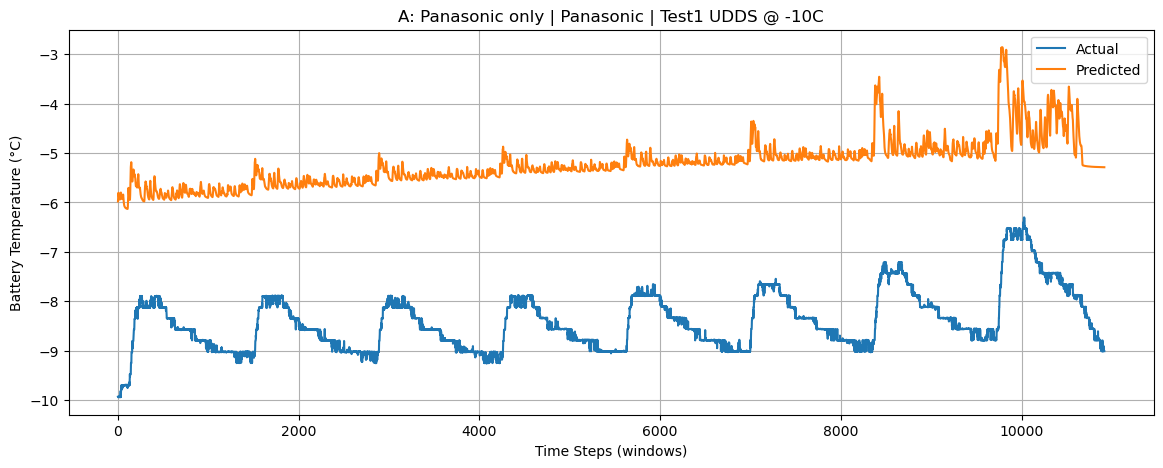

In [24]:
# Actual vs predicted for one test set with the final model
def plot_prediction(exp, data_dict, title):
    arr = build_arrays(data_dict, exp["feature_scaler"], exp["target_scaler"], stride=1)
    pred = exp["target_scaler"].inverse_transform(
        exp["model"].predict(arr["X"], batch_size=512, verbose=0)).flatten() + arr["tamb"]

    plt.figure(figsize=(14, 5))
    plt.plot(arr["temp"], label="Actual")
    plt.plot(pred, label="Predicted")
    plt.xlabel("Time Steps (windows)")
    plt.ylabel("Battery Temperature (°C)")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

final_label = list(experiments)[-1]
for set_name, d in test_sets.items():
    plot_prediction(experiments[final_label], d, f"{final_label} | {set_name}")

# Step 10 — Save everything the website needs

Besides the model and scalers, the config stores the **training ranges** of every feature. The website uses them to warn the user when an uploaded dataset is far outside what the model has seen.

In [25]:
final = experiments[final_label]

final["model"].save(os.path.join(OUTPUT_DIR, "cnn_lstm_universal.keras"))
joblib.dump(final["feature_scaler"], os.path.join(OUTPUT_DIR, "feature_scaler.pkl"))
joblib.dump(final["target_scaler"],  os.path.join(OUTPUT_DIR, "target_scaler.pkl"))

X_raw = np.concatenate([df[FEATURE_COLUMNS].values for df in final["train_dict"].values()])
lo, hi = np.percentile(X_raw, 0.5, axis=0), np.percentile(X_raw, 99.5, axis=0)

config = {
    "schema_version": 2,
    "trained_on": final["train_sources"],
    "feature_columns": FEATURE_COLUMNS,
    "mask_columns": MASK_COLUMNS,
    "target": "delta_temp_degC (T_surface - T_ambient)",
    "tamb_index": TAMB_IDX,
    "resample_dt_s": RESAMPLE_DT_S,
    "window_length": WINDOW_LENGTH,
    "default_capacity_ah": DEFAULT_CAPACITY_AH,
    "feature_ranges": {c: [float(a), float(b)] for c, a, b in zip(FEATURE_COLUMNS, lo, hi)},
}
with open(os.path.join(OUTPUT_DIR, "model_config.json"), "w") as f:
    json.dump(config, f, indent=2)

results_df.to_csv(os.path.join(OUTPUT_DIR, "validation_results.csv"), index=False)
print("Saved to:", OUTPUT_DIR)

Saved to: C:\Users\medha\OneDrive\Documents\TrustSenseBMS\artifacts


# Step 11 — Inference on an uploaded dataset (this is what the website calls)

In [26]:
def load_artifacts(output_dir=OUTPUT_DIR):
    model = load_model(os.path.join(output_dir, "cnn_lstm_universal.keras"))
    feature_scaler = joblib.load(os.path.join(output_dir, "feature_scaler.pkl"))
    target_scaler  = joblib.load(os.path.join(output_dir, "target_scaler.pkl"))
    with open(os.path.join(output_dir, "model_config.json")) as f:
        cfg = json.load(f)
    return model, feature_scaler, target_scaler, cfg

In [27]:
def predict_uploaded_dataset(df_raw, artifacts, column_map=None, capacity_ah=None,
                             ambient_temp_degC=None, n_series=1, n_parallel=1,
                             current_sign="discharge_negative", time_unit="auto",
                             sample_rate_hz=None):
    """
    df_raw: the uploaded table as a DataFrame (any column names / units / extra columns).
    Returns (result_df, report). result_df is on the resampled time grid; the first
    (window_length - 1) seconds of each segment have no prediction (NaN).
    """
    model, feature_scaler, target_scaler, cfg = artifacts
    window, dt = cfg["window_length"], cfg["resample_dt_s"]

    # 1) map columns, fix units, enforce one-cell / discharge-negative convention
    df_std, report = standardize_uploaded_df(
        df_raw, column_map=column_map, n_series=n_series, n_parallel=n_parallel,
        current_sign=current_sign, time_unit=time_unit,
        sample_rate_hz=sample_rate_hz, ambient_temp_degC=ambient_temp_degC)

    if capacity_ah is None:
        capacity_ah = cfg["default_capacity_ah"]
        report["warnings"].append(f"No cell capacity given: assumed {capacity_ah} Ah. "
                                  "C-rate (and so the heating estimate) depends on it.")

    # 2) clean -> common time grid -> features
    segments = resample_to_fixed_dt(clean_battery_df(df_std), dt=dt)
    if not segments:
        raise ValueError("Not enough valid rows after cleaning.")

    results = []
    for k, seg in enumerate(segments):
        seg = add_features(seg, capacity_ah, tamb_available=float(report["tamb_available"]), dt=dt)
        if len(seg) < window:
            report["warnings"].append(f"Segment {k} is shorter than {window} s and was skipped.")
            continue

        X = np.hstack([feature_scaler.transform(seg[cfg["feature_columns"]].values),
                       seg[cfg["mask_columns"]].values])
        X_seq, _ = create_sequences(X, np.zeros(len(X)), window, 1)

        pred_delta = target_scaler.inverse_transform(
            model.predict(X_seq, batch_size=512, verbose=0)).flatten()

        out = pd.DataFrame({"segment": k, "time_s": seg["time_s"],
                            "ambient_temp_degC": seg["chamber_temp_degC"],
                            "predicted_surface_temp_degC": np.nan})
        out.loc[window - 1:, "predicted_surface_temp_degC"] = pred_delta + seg["chamber_temp_degC"].values[window - 1:]
        out["measured_surface_temp_degC"] = seg["battery_temp_degC"]

        # 3) out-of-distribution check against the training ranges
        for col in cfg["feature_columns"]:
            low, high = cfg["feature_ranges"][col]
            margin = 0.1 * (high - low)
            frac = float(((seg[col] < low - margin) | (seg[col] > high + margin)).mean())
            if frac > 0.05:
                report["warnings"].append(
                    f"Segment {k}: {frac:.0%} of rows have '{col}' outside the range seen in training "
                    f"[{low:.2f}, {high:.2f}] -> treat predictions with caution.")
        results.append(out)

    result_df = pd.concat(results, ignore_index=True)

    # 4) metrics only if the upload had a surface-temperature column
    ok = result_df.dropna(subset=["predicted_surface_temp_degC", "measured_surface_temp_degC"])
    if len(ok):
        report["metrics"] = {
            "MAE_degC": float(mean_absolute_error(ok["measured_surface_temp_degC"], ok["predicted_surface_temp_degC"])),
            "RMSE_degC": float(np.sqrt(mean_squared_error(ok["measured_surface_temp_degC"], ok["predicted_surface_temp_degC"]))),
        }

    return result_df, report

# ### Example: simulate an upload (different names, mV / mA units, no ambient column, extra column)

In [28]:
# Take a Panasonic test file and disguise it like a foreign dataset
name = list(test_sets[list(test_sets)[0]])[0]
sample = test_sets[list(test_sets)[0]][name]

uploaded = pd.DataFrame({
    "Test_Time(s)":    sample["time_s"],
    "Cell Voltage (mV)": sample["voltage_v"] * 1000,       # mV, not V
    "Current (mA)":    sample["current_a"] * 1000,         # mA, not A
    "Cell_Temp":       sample["battery_temp_degC"],        # kept only to compute validation metrics
    "Cycle_Index":     1,                                  # extra column -> ignored
})

artifacts = load_artifacts()
result_df, report = predict_uploaded_dataset(uploaded, artifacts, capacity_ah=2.9,
                                             ambient_temp_degC=float(sample["chamber_temp_degC"].iloc[0]))

print("Mapped columns :", report["mapping"])
print("Ignored columns:", report["ignored_columns"])
print("Metrics        :", report.get("metrics"))
for w in report["warnings"]:
    print("WARNING:", w)
result_df.head()

Mapped columns : {'battery_temp_degC': 'Cell_Temp', 'time_s': 'Test_Time(s)', 'voltage_v': 'Cell Voltage (mV)', 'current_a': 'Current (mA)'}
Ignored columns: ['Cycle_Index']
Metrics        : {'MAE_degC': 3.175974098203487, 'RMSE_degC': 3.2143677041599146}


,segment,time_s,ambient_temp_degC,predicted_surface_temp_degC,measured_surface_temp_degC
0,0,0.0,-10.0,NaN,-10.158136
1,0,1.0,-10.0,NaN,-10.154353
2,0,2.0,-10.0,NaN,-10.150569
3,0,3.0,-10.0,NaN,-10.158136
4,0,4.0,-10.0,NaN,-10.158136
